In [12]:
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))

import corpora
from evaluation import competitors
from evaluation import scoring as report
from schemaoracle import cache, inventory

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

CORPUS = "gdc"
RETRIEVER = "qwen"
ARMS = ["rerank", "gated", "paged"]
FILTERS = {"": "no filter", "mutual": "mutual", "zero": "zero",
           "mutual-zero": "mutual+zero"}
CORPORA = [CORPUS]
METRICS = {"mrr": "MRR", "mrr_abstain": "MRR, abstention credited",
           "recall@1": "Recall@1", "recall@gt": "Recall@GT"}
MODELS = {
          #"deepseek-v4-flash-cloud": ("DeepSeek V4 Flash", "#2563eb"),
          "deepseek-v4.1-flash-cloud": ("DeepSeek V4.1 Flash", "#56b4e9"),
          #"deepseek-v4-pro-cloud": ("DeepSeek V4 Pro", "#d55e00"),
          #"jev-1.13": ("Jev 1.13", "#cc79a7"),
          #"claude-sonnet-5": ("Sonnet 5", "#0f766e")
}
VARIANTS = ["tgt-match-retriever__retry3", "tgt-match-retriever"]
#VARIANTS = ["tgt-match-retriever"]
TOP_K, WINDOW, TAU = 20, 20, 0.0
COMPETITORS = {
    "coma": "COMA",
    "coma-instances": "COMA, instances",
    "jaccard-levenshtein": "Jaccard-Levenshtein",
    competitors.magneto_llm_tag(RETRIEVER, "deepseek/deepseek-v4.1-flash"):
        "Magneto + LLM (V4.1 Flash)",
}

RUNS = REPO / "results" / "runs"
COMPETITOR_RUNS = REPO / "results" / "competitors"
FIGDIR = REPO / "figures"
OUT = REPO / "results" / "metrics_compare_pairs.csv"

C_INK, C_MUTE, C_COMP = "#1e293b", "#94a3b8", "#475569"
mpl.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 400, "savefig.bbox": "tight",
    "font.family": "serif", "font.serif": ["DejaVu Serif"], "font.size": 7.5,
    "text.color": C_INK, "xtick.color": C_INK, "ytick.color": C_INK,
    "axes.edgecolor": C_INK, "axes.labelcolor": C_INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.16, "grid.linewidth": 0.4,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})

PAIRS = {c: corpora.load(c) for c in CORPORA}
for c, pairs in PAIRS.items():
    print(f"{c}: {len(pairs)} pairs, "
          f"{sum(p['source_df'].shape[1] for p in pairs)} source columns")
print(f"{RETRIEVER} order, tau = {TAU:.2f}, filters {list(FILTERS.values())}")

gdc: 10 pairs, 569 source columns
qwen order, tau = 0.00, filters ['no filter', 'mutual', 'zero', 'mutual+zero']


In [13]:
def tagged(frame):
    return frame.assign(model=frame["arm"].str.split("__").str[0],
                        variant=frame["arm"].str.split("__").str[1:].str.join("__"))


def per_pair(row, corpus, **cell):
    return {"corpus": corpus, **cell, "pair": row["pair"],
            **{m: row[m] for m in METRICS}}


rows, cells, partial = [], [], []
for corpus, pairs in PAIRS.items():
    names = [cache.fs_safe(p["name"]) for p in pairs]
    n_src = sum(p["source_df"].shape[1] for p in pairs)
    inv = tagged(inventory.scan(RUNS, corpus=corpus, pairs=names, kinds=tuple(ARMS)))
    inv = inv[(inv["retriever"] == RETRIEVER) & inv["prune"].isin(FILTERS)
              & (inv["rep"] == 1) & inv["model"].isin(MODELS)
              & inv["variant"].isin(VARIANTS)
              & ((inv["kind"] != "paged") & (inv["top_k"] == TOP_K)
                 | (inv["kind"] == "paged") & (inv["window"] == WINDOW)
                 & (inv["threshold"] == TAU))]
    ok = tagged(inventory.check(inv, verbose=False))
    for f in FILTERS:
        for arm in ARMS:
            for m, (name, colour) in MODELS.items():
                cell = {"method": f"{arm} / {name}", "group": arm,
                        "colour": colour, "filter": f}
                whole, best = False, None
                for v in VARIANTS:
                    runs = ok[(ok["kind"] == arm) & (ok["model"] == m)
                              & (ok["variant"] == v) & (ok["prune"] == f)]
                    if not len(runs):
                        continue
                    if (set(runs["pair"]) == set(names)
                            and runs["n_columns"].sum() == n_src):
                        s = report.score(runs, pairs, results=RUNS, corpus=corpus,
                                         kind=arm, ceiling=False, group_by="pair")
                        rows += [per_pair(r, corpus, **cell) for _, r in s.iterrows()]
                        whole = True
                        break
                    if best is None or runs["n_columns"].sum() > best["n_columns"].sum():
                        best = runs
                # Scored on what is on disk and plotted like any other cell.
                # The bar is a mean over the studies that are present, so it
                # rests on fewer columns than a whole cell; how many fewer is
                # on the figure and in the table below.
                if not whole and best is not None:
                    s = report.score(best, pairs, results=RUNS, corpus=corpus,
                                     kind=arm, ceiling=False, group_by="pair")
                    rows += [per_pair(r, corpus, **cell) for _, r in s.iterrows()]
                    have = int(best["n_columns"].sum())
                    partial.append({"corpus": corpus, "method": cell["method"],
                                    "filter": f, "studies": len(set(best["pair"])),
                                    "of_studies": len(names), "columns": have,
                                    "needs": n_src - have,
                                    **{k: s[k].mean() for k in METRICS}})
                cells.append({"corpus": corpus, **cell, "whole": whole})
OURS = pd.DataFrame(rows)
print(f"{int(pd.DataFrame(cells)['whole'].sum())} of {len(cells)} arm cells whole")


12 of 12 arm cells whole


In [14]:
for corpus, pairs in PAIRS.items():
    n_src = sum(p["source_df"].shape[1] for p in pairs)
    for p in pairs:
        order, gt = report.retrieval_rankings([p], results=RUNS, corpus=corpus,
                                              retriever=RETRIEVER)
        r = report.metrics(order, gt, {c: True for c in order})
        rows.append({"corpus": corpus, "method": "retriever alone",
                     "group": "retriever", "colour": C_MUTE, "filter": "",
                     "pair": cache.fs_safe(p["name"]),
                     **{m: r[m] for m in METRICS}})
    cells.append({"corpus": corpus, "method": "retriever alone",
                  "group": "retriever", "colour": C_MUTE, "filter": "",
                  "whole": True})
    for tag, name in COMPETITORS.items():
        got, have = [], 0
        for p in pairs:
            s = report.score_competitors([p], [tag], results=COMPETITOR_RUNS,
                                         corpus=corpus, retriever=RETRIEVER)
            if len(s):
                have += int(s.iloc[0]["n_columns"])
                got.append({"corpus": corpus, "method": name,
                            "group": "competitor", "colour": C_COMP,
                            "filter": "", "pair": cache.fs_safe(p["name"]),
                            **{m: s.iloc[0][m] for m in METRICS}})
        whole = len(got) == len(pairs) and have == n_src
        if whole:
            rows += got
        elif got:
            rows += got
            g = pd.DataFrame(got)
            partial.append({"corpus": corpus, "method": name, "filter": "",
                            "studies": len(g), "of_studies": len(pairs),
                            "columns": have, "needs": n_src - have,
                            **{k: g[k].mean() for k in METRICS}})
        cells.append({"corpus": corpus, "method": name, "group": "competitor",
                      "colour": C_COMP, "filter": "", "whole": whole})

PER_PAIR = pd.DataFrame(rows)
CELLS = pd.DataFrame(cells)
PARTIAL = pd.DataFrame(partial)
q = PER_PAIR.groupby(["corpus", "filter", "group", "method"], sort=False)
SUMMARY = pd.concat(
    [q[list(METRICS)].mean().add_suffix("_mean"),
     # ddof=1: the pairs are a sample of the corpus, not the whole of it.
     q[list(METRICS)].std(ddof=1).add_suffix("_std"),
     q[list(METRICS)].quantile(0.25).add_suffix("_q1"),
     q[list(METRICS)].quantile(0.75).add_suffix("_q3"),
     q.size().rename("n_pairs")], axis=1).reset_index()
PER_PAIR.drop(columns="colour").to_csv(OUT, index=False)
SUMMARY.to_csv(OUT.with_name("metrics_compare_summary.csv"), index=False)

short = {(r.corpus, r.method, r.filter): r for r in PARTIAL.itertuples()}
for r in CELLS[~CELLS["whole"]].itertuples():
    where = f"{r.corpus} / {r.method} / {FILTERS[r.filter]}"
    s = short.get((r.corpus, r.method, r.filter))
    if s is None:
        print(f"not whole: {where}: nothing on disk")
    else:
        # Two different shortfalls: studies the health check excluded, and
        # columns simply not run. Report both rather than conflate them.
        print(f"not whole: {where}: {s.studies} of {s.of_studies} studies, "
              f"{s.columns:,} of {s.columns + s.needs:,} columns; the bar "
              f"is what is on disk")
def pm(row, metric):
    """`mean +/- std` for one metric, or the mean alone for a single pair."""
    sd = row[f"{metric}_std"]
    return (f"{row[f'{metric}_mean']:.3f}"
            + ("" if pd.isna(sd) else f" +/- {sd:.3f}"))


# `to_dict`, not `itertuples`: the latter renames any column that is not a
# valid identifier, and every metric here has one (`recall@1`).
PLUS_MINUS = pd.DataFrame([
    {"corpus": r["corpus"], "filter": FILTERS[r["filter"]],
     "method": r["method"], "pairs": int(r["n_pairs"]),
     **{m: pm(r, m) for m in METRICS}}
    for r in SUMMARY.to_dict("records")])
display(PLUS_MINUS)
if len(PARTIAL):
    print("")
    print("the not-whole cells are drawn from what is on disk, over fewer "
          "columns than a whole cell, so read them against the shortfall:")
    display(PARTIAL.drop(columns="of_studies").round(3))
print(f"wrote {OUT} and {OUT.with_name('metrics_compare_summary.csv')}")


def shown(frame, corpus, f):
    fixed = frame["group"].isin(["retriever", "competitor"])
    return frame[(frame["corpus"] == corpus)
                 & (fixed | (frame["filter"] == f))]


,corpus,filter,method,pairs,mrr,mrr_abstain,recall@1,recall@gt
0,gdc,no filter,rerank / DeepSeek V4.1 Flash,10,0.877 +/- 0.082,0.389 +/- 0.264,0.520 +/- 0.092,0.638 +/- 0.091
1,gdc,no filter,gated / DeepSeek V4.1 Flash,10,0.888 +/- 0.097,0.466 +/- 0.207,0.532 +/- 0.084,0.633 +/- 0.089
2,gdc,no filter,paged / DeepSeek V4.1 Flash,10,0.910 +/- 0.064,0.489 +/- 0.219,0.549 +/- 0.081,0.614 +/- 0.116
3,gdc,mutual,rerank / DeepSeek V4.1 Flash,10,0.822 +/- 0.107,0.641 +/- 0.072,0.493 +/- 0.081,0.610 +/- 0.100
4,gdc,mutual,gated / DeepSeek V4.1 Flash,10,0.818 +/- 0.102,0.681 +/- 0.062,0.491 +/- 0.080,0.608 +/- 0.105
5,gdc,mutual,paged / DeepSeek V4.1 Flash,10,0.838 +/- 0.083,0.692 +/- 0.068,0.505 +/- 0.079,0.606 +/- 0.122
6,gdc,zero,rerank / DeepSeek V4.1 Flash,10,0.878 +/- 0.082,0.390 +/- 0.264,0.522 +/- 0.094,0.587 +/- 0.108
7,gdc,zero,gated / DeepSeek V4.1 Flash,10,0.893 +/- 0.088,0.464 +/- 0.220,0.537 +/- 0.086,0.628 +/- 0.131
8,gdc,zero,paged / DeepSeek V4.1 Flash,10,0.901 +/- 0.070,0.518 +/- 0.199,0.540 +/- 0.081,0.635 +/- 0.127
9,gdc,mutual+zero,rerank / DeepSeek V4.1 Flash,10,0.812 +/- 0.087,0.641 +/- 0.070,0.483 +/- 0.084,0.568 +/- 0.128


wrote C:\Users\muril\SchemaOracle\results\metrics_compare_pairs.csv and C:\Users\muril\SchemaOracle\results\metrics_compare_summary.csv


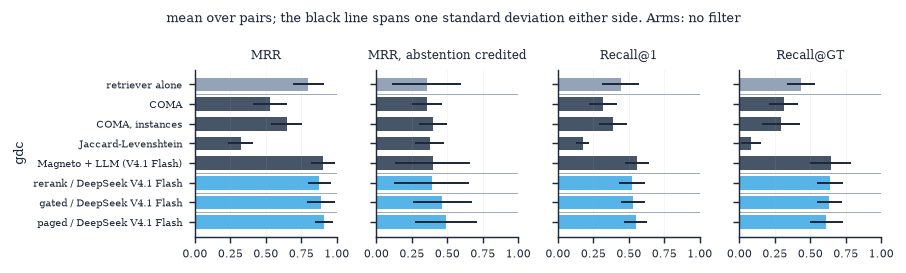

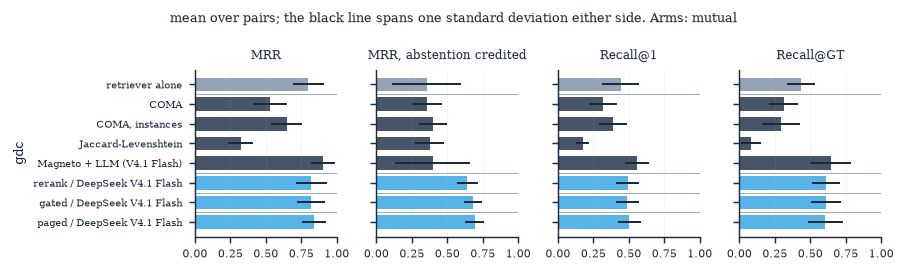

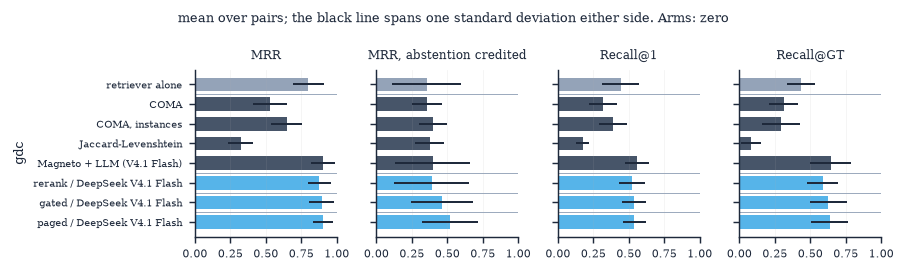

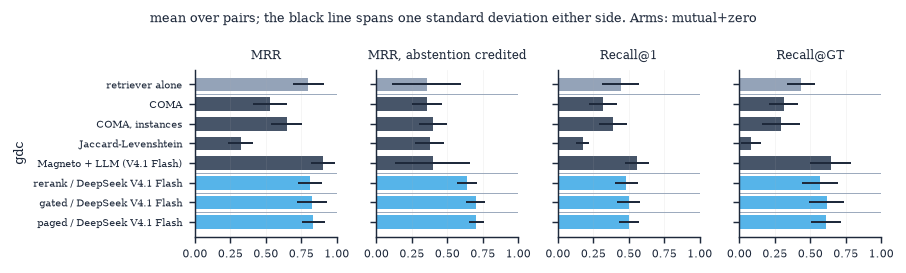

In [15]:
GROUP_ORDER = ["retriever", "competitor"] + ARMS
# What a partial cell is short of: whole studies the health check excluded,
# or columns never run. They are different and read differently.
EXCLUDED = {(r.method, r.filter):
            (f"partial: {r.studies} of {r.of_studies} studies"
             if r.studies < r.of_studies else
             f"partial: {r.columns:,} of {r.columns + r.needs:,} columns")
            for r in PARTIAL.itertuples()}
n_rows = 1 + len(COMPETITORS) + len(ARMS) * len(MODELS)
for f, flabel in FILTERS.items():
    fig, axes = plt.subplots(len(CORPORA), len(METRICS), sharex=True,
                             squeeze=False,
                             figsize=(7.0, len(CORPORA) * (0.17 * n_rows + 0.7)))
    for i, corpus in enumerate(CORPORA):
        C = shown(CELLS, corpus, f)
        C = (C.assign(order=C["group"].map(GROUP_ORDER.index))
             .sort_values("order", kind="stable").iloc[::-1].reset_index(drop=True))
        S = shown(SUMMARY, corpus, f).set_index("method")
        for j, (metric, title) in enumerate(METRICS.items()):
            ax = axes[i, j]
            for k, r in C.iterrows():
                if r["method"] not in S.index:
                    ax.text(0.01, k, "never run" if j else
                            "not whole, never run", va="center", fontsize=5,
                            color=C_MUTE)
                    continue
                s = S.loc[r["method"]]
                mu, sd = s[f"{metric}_mean"], s[f"{metric}_std"]
                ax.barh(k, mu, height=0.7, color=r["colour"])
                # Clipped to the axis: every metric here lives in [0, 1], and a
                # mean near either end has a bar that would run off it.
                if pd.notna(sd):
                    ax.hlines(k, max(mu - sd, 0.0), min(mu + sd, 1.0),
                              color=C_INK, lw=1.1)
                # Drawn like any other bar, but over fewer studies, so say
                # how many were left out rather than leave it implicit.
                gap = EXCLUDED.get((r["method"], r["filter"]))
                if gap and j == 0:
                    ax.text(0.985, k, gap, ha="right", va="center",
                            fontsize=4.4, color=C_MUTE)
            groups = C["group"].to_numpy()
            for b in np.where(groups[1:] != groups[:-1])[0]:
                ax.axhline(b + 0.5, color=C_MUTE, lw=0.5)
            ax.set_xlim(0, 1.0)
            ax.grid(axis="y", visible=False)
            ax.tick_params(axis="x", labelsize=6)
            if i == 0:
                ax.set_title(title, fontsize=6.8)
            ax.set_yticks(range(len(C)), C["method"] if j == 0 else [""] * len(C))
            ax.tick_params(axis="y", labelsize=5.8)
        axes[i, 0].set_ylabel(corpus, fontsize=7)
    fig.suptitle("mean over pairs; the black line spans one standard "
                 f"deviation either side. Arms: {flabel}", fontsize=7)
    fig.tight_layout()
    for ext in ("pdf", "png"):
        fig.savefig(FIGDIR / f"compare_competitors_pairs_{cache.fs_safe(f or 'none')}.{ext}")
    plt.show()